Import Dataset (PlantVillage dataset)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


Import Libraries

In [2]:
import os
import random
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


Load the image dataset



In [3]:
import tensorflow as tf

base_dataset_path = '/kaggle/input/plantvillage-dataset/plantvillage dataset'

Display contents of base directory

In [4]:
print("Contents of base directory:")
print(os.listdir(base_dataset_path))

Contents of base directory:
['segmented', 'grayscale', 'color']


Number of classes and the number of images in each class

In [5]:
color_path = os.path.join(base_dataset_path, 'color')

print("Number of disease/crop folders:",
      len(os.listdir(color_path)))

print("\nFirst 20 folders:")

for folder in sorted(os.listdir(color_path))[:20]:
    print(folder)

Number of disease/crop folders: 38

First 20 folders:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy


In [6]:
class_names = sorted(os.listdir(color_path))

print("Number of classes:", len(class_names))
print(class_names)

Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite

Save metadata

In [7]:
# Create metadata DataFrame from the PlantVillage color dataset

image_paths = []
labels = []

for class_id, class_name in enumerate(class_names):

    class_folder = os.path.join(color_path, class_name)

    for filename in os.listdir(class_folder):

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_paths.append(
                os.path.join(class_folder, filename)
            )

            labels.append(class_id)

metadata = pd.DataFrame({
    "image_path": image_paths,
    "class_id": labels
})

metadata["class_name"] = metadata["class_id"].map(
    dict(enumerate(class_names))
)

print("Metadata created successfully!")
print("Total images:", len(metadata))
print(metadata.head())

Metadata created successfully!
Total images: 54305
                                          image_path  class_id  \
0  /kaggle/input/plantvillage-dataset/plantvillag...         0   
1  /kaggle/input/plantvillage-dataset/plantvillag...         0   
2  /kaggle/input/plantvillage-dataset/plantvillag...         0   
3  /kaggle/input/plantvillage-dataset/plantvillag...         0   
4  /kaggle/input/plantvillage-dataset/plantvillag...         0   

           class_name  
0  Apple___Apple_scab  
1  Apple___Apple_scab  
2  Apple___Apple_scab  
3  Apple___Apple_scab  
4  Apple___Apple_scab  


In [8]:
print(metadata.head())
print(metadata.shape)

                                          image_path  class_id  \
0  /kaggle/input/plantvillage-dataset/plantvillag...         0   
1  /kaggle/input/plantvillage-dataset/plantvillag...         0   
2  /kaggle/input/plantvillage-dataset/plantvillag...         0   
3  /kaggle/input/plantvillage-dataset/plantvillag...         0   
4  /kaggle/input/plantvillage-dataset/plantvillag...         0   

           class_name  
0  Apple___Apple_scab  
1  Apple___Apple_scab  
2  Apple___Apple_scab  
3  Apple___Apple_scab  
4  Apple___Apple_scab  
(54305, 3)


In [9]:
from collections import Counter

ds = tf.keras.utils.image_dataset_from_directory(
    color_path,
    labels="inferred",
    label_mode="int",
    image_size=(224, 224),
    interpolation="nearest",
    batch_size=32,
    shuffle=True,
    seed=42
)

class_names = ds.class_names

print("Number of classes:", len(class_names))
print("Total batches:", tf.data.experimental.cardinality(ds).numpy())
print("Classes:")
for i, name in enumerate(class_names):
    print(i, name)

class_counts = Counter()

for images, labels in ds:
    for label in labels.numpy():
        class_counts[int(label)] += 1

for class_id, count in sorted(class_counts.items()):
    print(f"{class_names[class_id]}: {count}")

Found 54305 files belonging to 38 classes.
Number of classes: 38
Total batches: 1698
Classes:
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Sept

In [10]:
num_images = 0

for images, labels in ds:
    num_images += images.shape[0]

print("Total images:", num_images)

Total images: 54305


### Visualize data

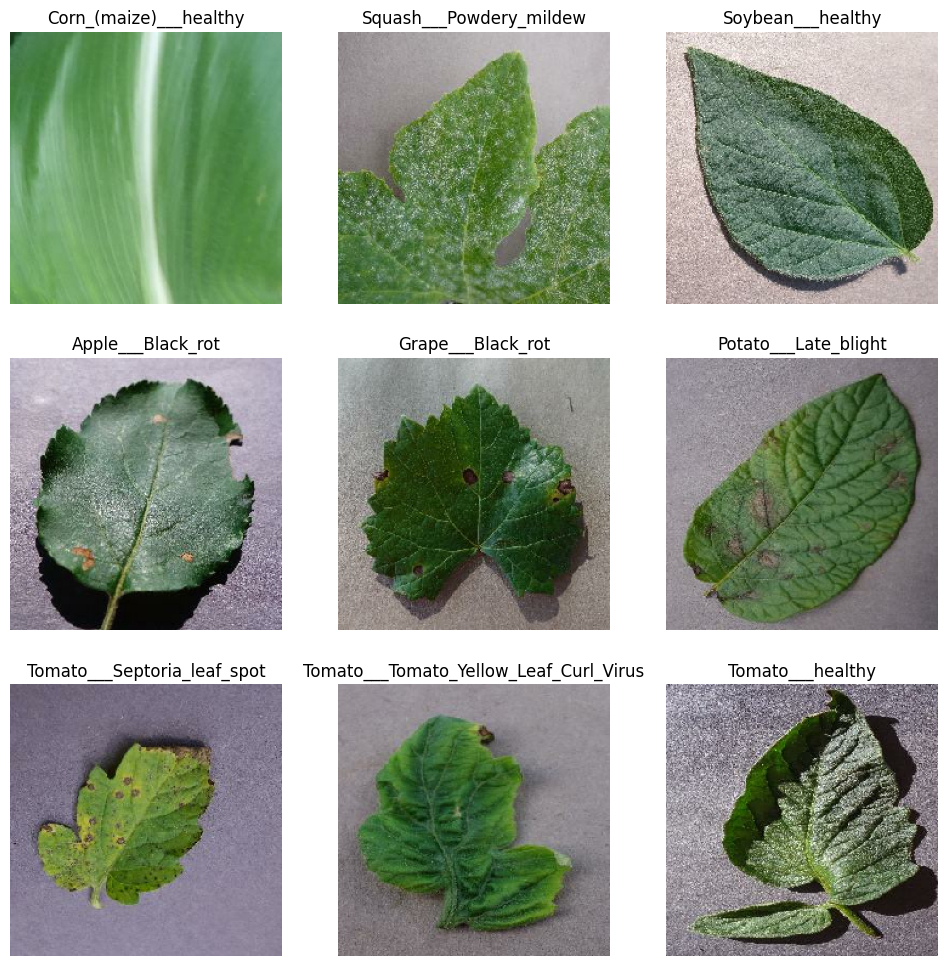

In [11]:
import matplotlib.pyplot as plt

for images, labels in ds.take(1):
    plt.figure(figsize=(12, 12))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.show()


In [12]:
class_distribution = metadata['class_name'].value_counts()

print(class_distribution)

class_name
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Soybean___healthy                                     5090
Peach___Bacterial_spot                                2297
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1909
Squash___Powdery_mildew                               1835
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Apple___healthy                                       1645
Tomato___healthy                                      1591
Blueberry___healthy                                   1502
Pepper,_bell___healthy                                1478
Tomato___Target_Spot                                  1404
Grape___Esca_(Black_Measles)                          1383
Corn_(maize)___Common_rust_                           1192
Grape___Black_rot                            

Visualize class distribution

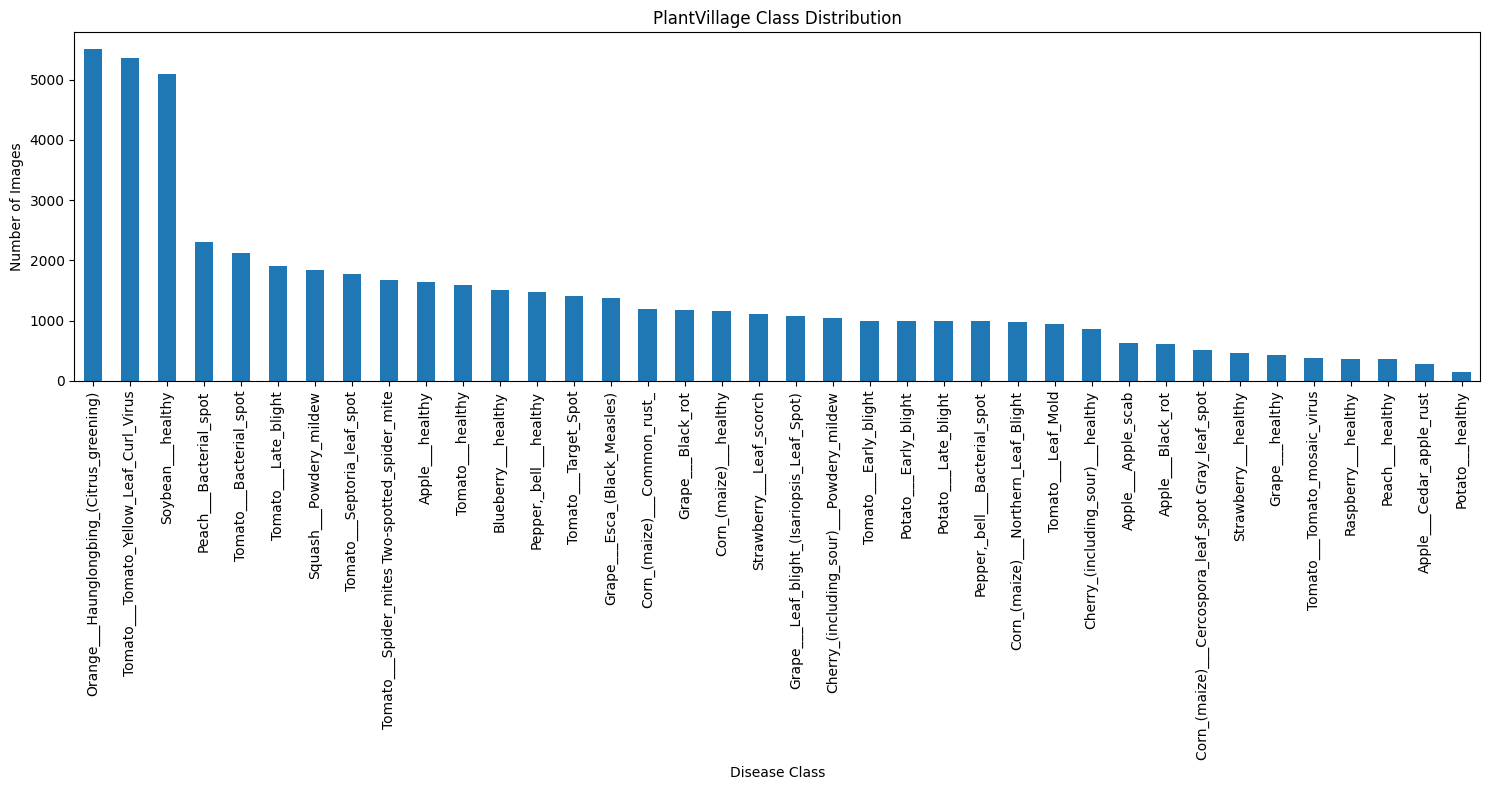

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

class_distribution.plot(kind='bar')

plt.title("PlantVillage Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### Train-Test Split

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
train_df, temp_df = train_test_split(
    metadata,
    test_size=0.30,
    stratify=metadata['class_id'],
    random_state=42
)

In [16]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['class_id'],
    random_state=42
)

Tensorflow datasets

In [17]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

In [18]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

In [19]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image_path"].values,
        val_df["class_id"].values
    )
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [20]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].values,
        test_df["class_id"].values
    )
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

In [21]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["image_path"].values,
        train_df["class_id"].values
    )
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_df),
    seed=42
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

In [22]:
images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32,)


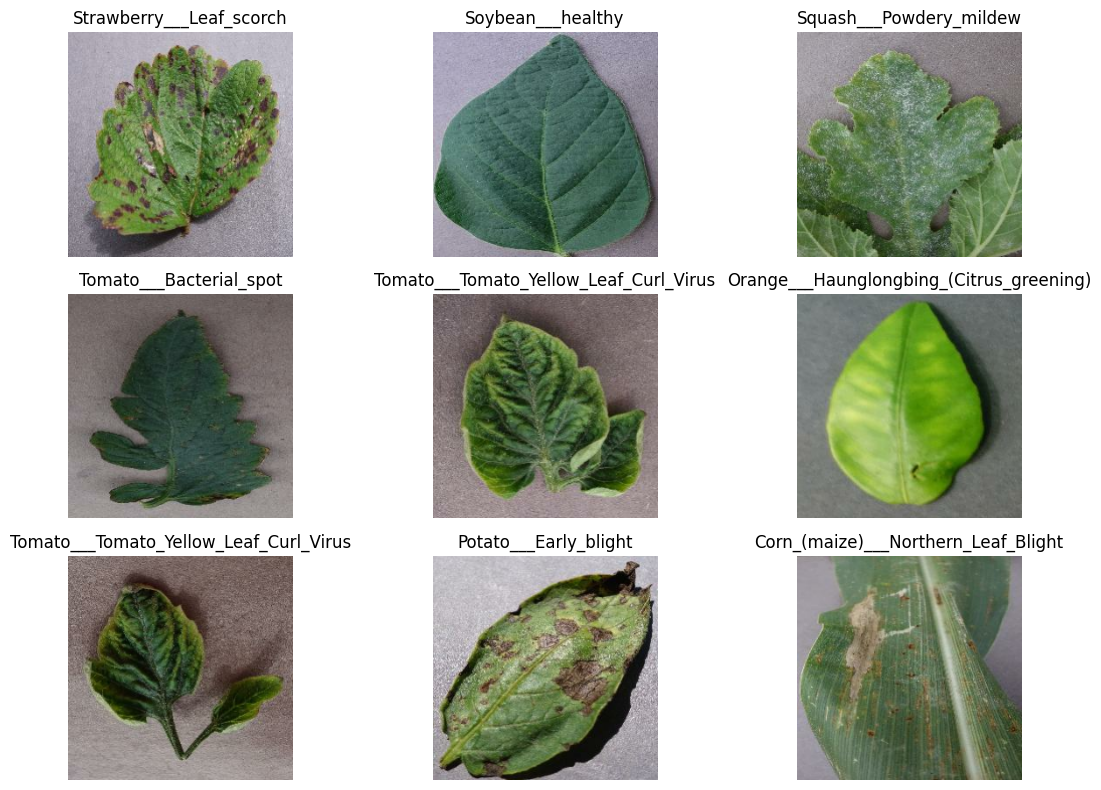

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

Data Augmentation

In [24]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
], name="data_augmentation")

Efficient-Net B0 Model

In [25]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model

In [26]:
NUM_CLASSES = len(class_names)

inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="leaf_image"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_prediction"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="PlantDisease_EfficientNetB0"
)

model.summary()

Model: "PlantDisease_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_prediction (Dense)      │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [27]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 132s 99ms/step - accuracy: 0.8387 - loss: 0.6860 - val_accuracy: 0.9239 - val_loss: 0.2808
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 115s 97ms/step - accuracy: 0.9261 - loss: 0.2712 - val_accuracy: 0.9429 - val_loss: 0.1984
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 116s 98ms/step - accuracy: 0.9377 - loss: 0.2154 - val_accuracy: 0.9502 - val_loss: 0.1660
Epoch 4/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 117s 98ms/step - accuracy: 0.9464 - loss: 0.1813 - val_accuracy: 0.9553 - val_loss: 0.1461
Epoch 5/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 121s 102ms/step - accuracy: 0.9481 - loss: 0.1679 - val_accuracy: 0.9561 - val_loss: 0.1344


Plot Training and Validation Accuracy and Loss

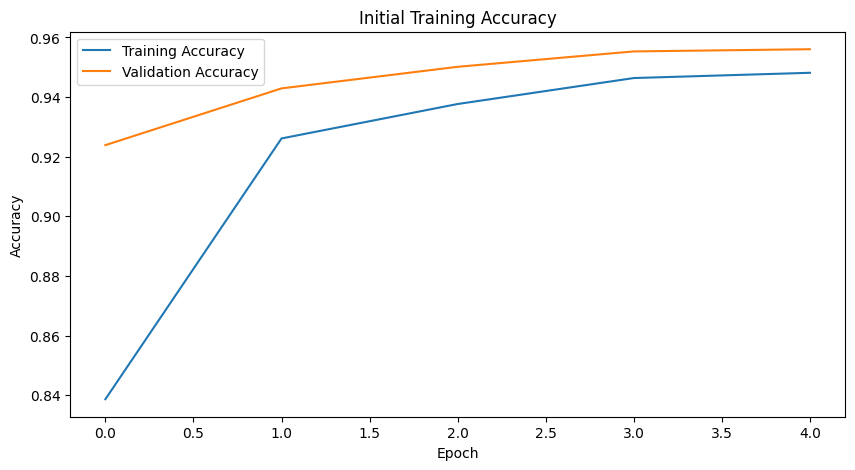

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_initial.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_initial.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Initial Training Accuracy")
plt.legend()
plt.show()

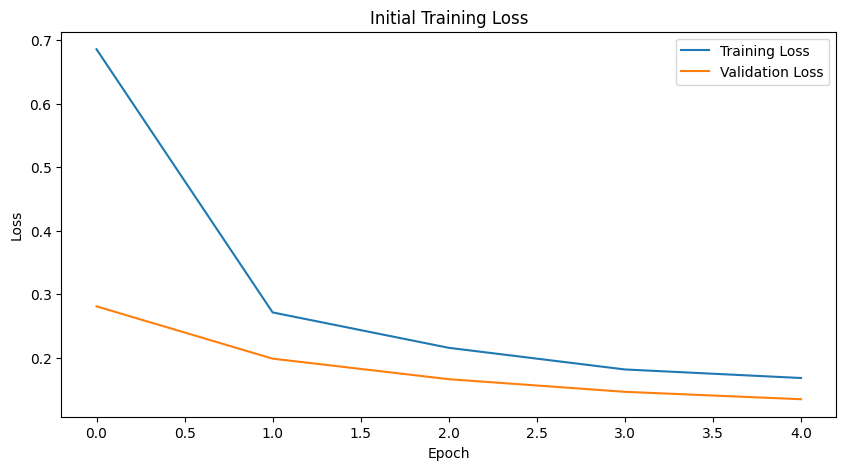

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_initial.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_initial.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Initial Training Loss")
plt.legend()
plt.show()

Fine tune the model

In [31]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [32]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Save checkpoints

In [33]:
checkpoint_path = "/kaggle/working/disease_efficientnet_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [34]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.8554 - loss: 0.5035
Epoch 1: val_accuracy improved from None to 0.94832, saving model to /kaggle/working/disease_efficientnet_best.keras

Epoch 1: finished saving model to /kaggle/working/disease_efficientnet_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 156s 119ms/step - accuracy: 0.8875 - loss: 0.3879 - val_accuracy: 0.9483 - val_loss: 0.1597 - learning_rate: 1.0000e-05
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9322 - loss: 0.2273
Epoch 2: val_accuracy improved from 0.94832 to 0.96109, saving model to /kaggle/working/disease_efficientnet_best.keras

Epoch 2: finished saving model to /kaggle/working/disease_efficientnet_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 136s 114ms/step - accuracy: 0.9351 - loss: 0.2166 - val_accuracy: 0.9611 - val_loss: 0.1235 - learning_rate: 1.0000e-05
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9470 - loss: 0.1755
Epoch 3: val_accuracy impro

Accuracy and Loss on Test dataset

In [35]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

255/255 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - accuracy: 0.9808 - loss: 0.0602
Test Loss: 0.06017385050654411
Test Accuracy: 0.9808495044708252


In [36]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.98      0.98        94
                                 Apple___Black_rot       0.99      0.99      0.99        93
                          Apple___Cedar_apple_rust       1.00      0.98      0.99        41
                                   Apple___healthy       0.99      0.99      0.99       246
                               Blueberry___healthy       0.99      1.00      0.99       226
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       158
                 Cherry_(including_sour)___healthy       1.00      0.99      1.00       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.96      0.65      0.78        77
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       179
               Corn_(maize)___Northern_Leaf_Blight       0.85      0.99      0.

Save keras, json and metadata

In [37]:
model.save(
    "/kaggle/working/disease_efficientnet.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [38]:
import json

class_mapping = {
    str(i): class_names[i]
    for i in range(len(class_names))
}

with open(
    "/kaggle/working/disease_class_names.json",
    "w"
) as f:
    json.dump(
        class_mapping,
        f,
        indent=4
    )

print("Class mapping JSON saved.")

Class mapping JSON saved.


In [39]:
model_metadata = {
    "model": "EfficientNetB0",
    "image_size": [224, 224],
    "number_of_classes": len(class_names),
    "classes": class_names,
    "dataset": "PlantVillage",
    "train_split": 0.70,
    "validation_split": 0.15,
    "test_split": 0.15
}

with open(
    "/kaggle/working/disease_metadata.json",
    "w"
) as f:
    json.dump(
        model_metadata,
        f,
        indent=4
    )

print("Metadata JSON saved.")

Metadata JSON saved.


Explainable AI

In [40]:
# XAI imports
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

EfficientNet feature layer

In [41]:
base_model = model.get_layer("efficientnetb0")

for layer in base_model.layers[-10:]:
    print(layer.name, layer.output.shape)

block7a_se_squeeze (None, 1152)
block7a_se_reshape (None, 1, 1, 1152)
block7a_se_reduce (None, 1, 1, 48)
block7a_se_expand (None, 1, 1, 1152)
block7a_se_excite (None, 7, 7, 1152)
block7a_project_conv (None, 7, 7, 320)
block7a_project_bn (None, 7, 7, 320)
top_conv (None, 7, 7, 1280)
top_bn (None, 7, 7, 1280)
top_activation (None, 7, 7, 1280)


Grad cam model

In [52]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

0 leaf_image InputLayer
1 data_augmentation Sequential
2 efficientnetb0 Functional
3 global_average_pooling2d GlobalAveragePooling2D
4 dropout Dropout
5 disease_prediction Dense


In [54]:
base_model = model.get_layer("efficientnetb0")

grad_model = tf.keras.models.Model(
    inputs=base_model.input,
    outputs=[
        base_model.get_layer("top_conv").output,
        base_model.output
    ]
)

print("Grad-CAM backbone model created successfully.")

Grad-CAM backbone model created successfully.


In [62]:
def make_gradcam_heatmap(image, model, base_model, pred_index=None):

    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:

        augmented_image = model.get_layer(
            "data_augmentation"
        )(image_batch, training=False)

        conv_outputs = base_model(
            augmented_image,
            training=False
        )

        x = tf.keras.layers.GlobalAveragePooling2D()(conv_outputs)

        predictions = model.get_layer(
            "disease_prediction"
        )(x, training=False)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy(), int(pred_index), predictions[0].numpy()

In [56]:
test_images, test_labels = next(iter(test_ds))

sample_image = test_images[0]
true_label = int(test_labels[0])

heatmap, predicted_class = make_gradcam_heatmap(
    sample_image,
    model,
    base_model
)

print("True class:", class_names[true_label])
print("Predicted class:", class_names[predicted_class])

True class: Tomato___Late_blight
Predicted class: Tomato___Late_blight


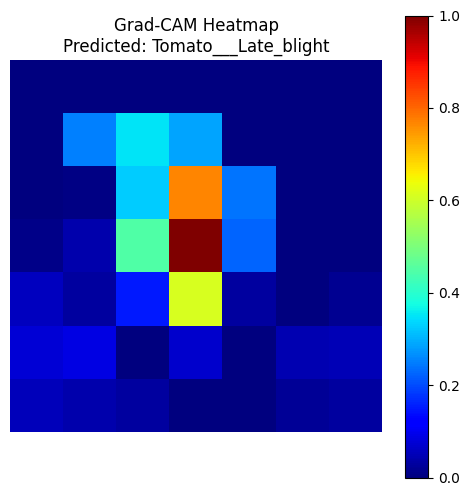

In [57]:
plt.figure(figsize=(6, 6))

plt.imshow(heatmap, cmap="jet")
plt.colorbar()

plt.title(
    f"Grad-CAM Heatmap\n"
    f"Predicted: {class_names[predicted_class]}"
)

plt.axis("off")
plt.show()

In [60]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

def display_gradcam(image, heatmap, predicted_class, true_class):

    image_uint8 = image.numpy().astype("uint8")

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (image_uint8.shape[0], image_uint8.shape[1])
    ).numpy().squeeze()

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image_uint8)
    plt.title(
        f"Original Image\n"
        f"True: {class_names[true_class]}"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(image_uint8)
    plt.imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )
    plt.title(
        f"Grad-CAM Explanation\n"
        f"Predicted: {class_names[predicted_class]}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

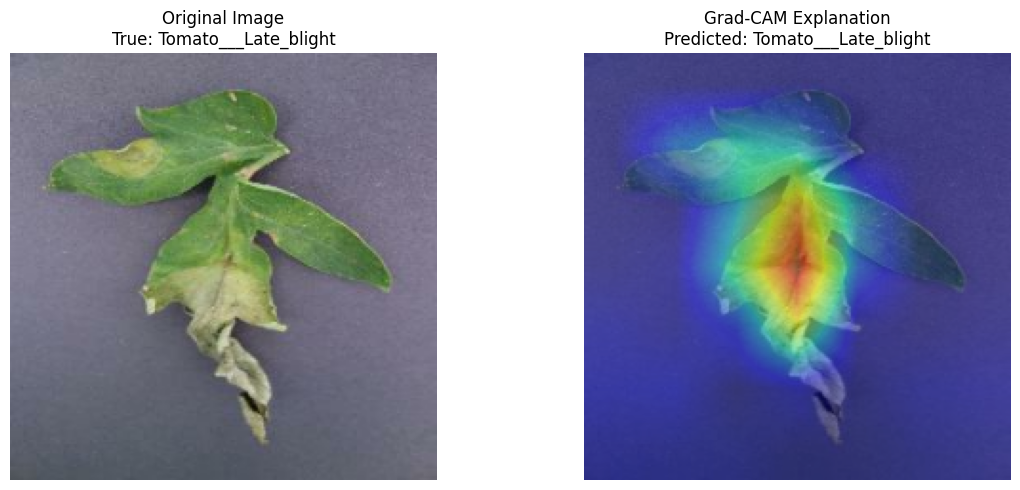

In [59]:
display_gradcam(
    sample_image,
    heatmap,
    predicted_class,
    true_label
)


Image 1
True disease     : Tomato___Late_blight
Predicted disease: Tomato___Late_blight
Confidence       : 99.74%


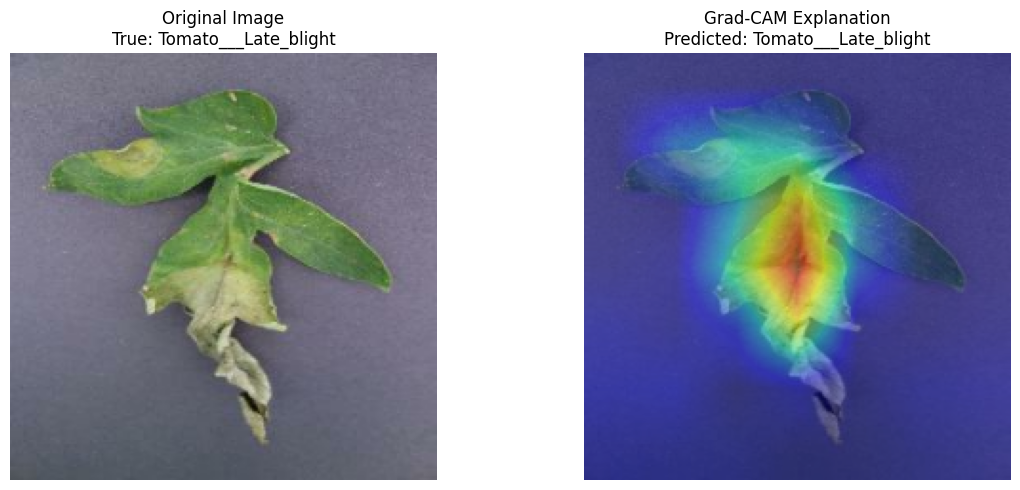


Image 2
True disease     : Soybean___healthy
Predicted disease: Soybean___healthy
Confidence       : 100.00%


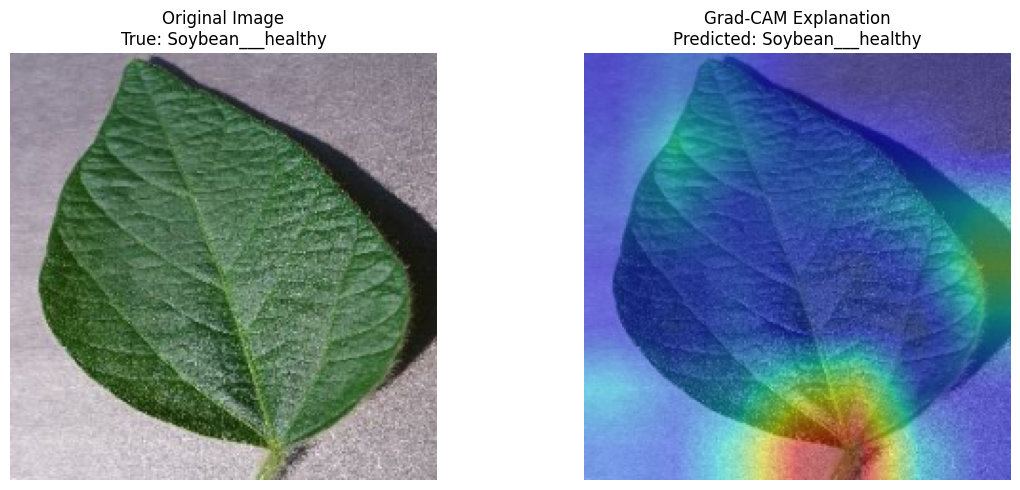


Image 3
True disease     : Tomato___Target_Spot
Predicted disease: Tomato___Target_Spot
Confidence       : 98.24%


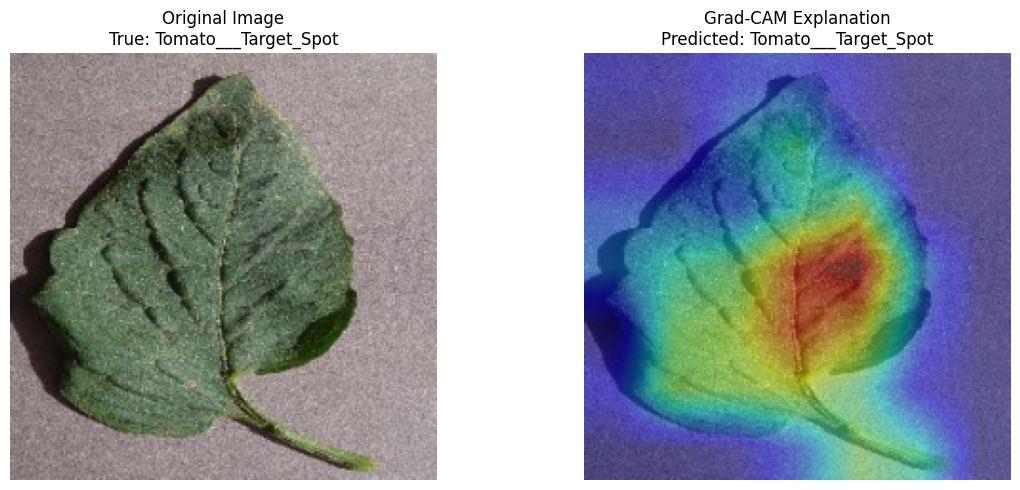


Image 4
True disease     : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Predicted disease: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Confidence       : 96.14%


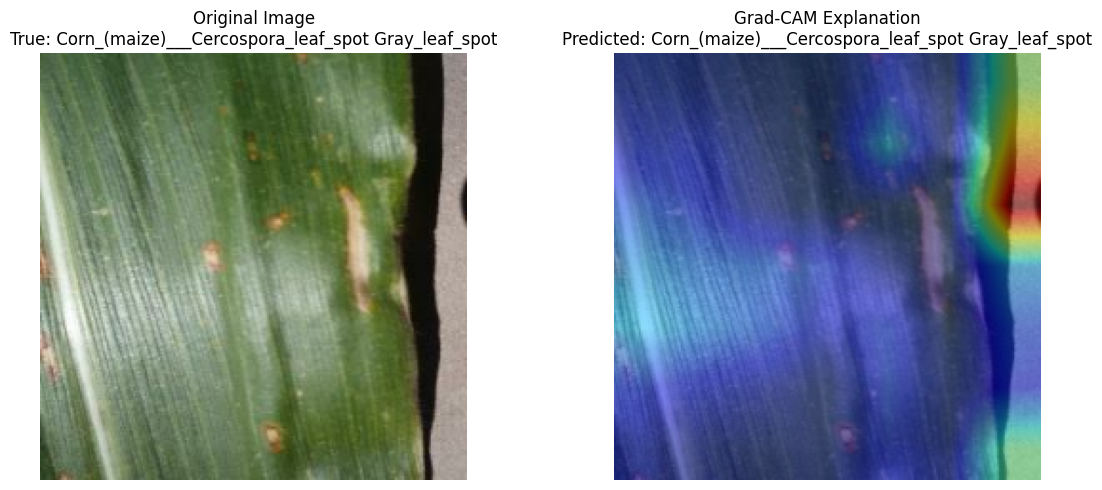


Image 5
True disease     : Apple___healthy
Predicted disease: Apple___healthy
Confidence       : 100.00%


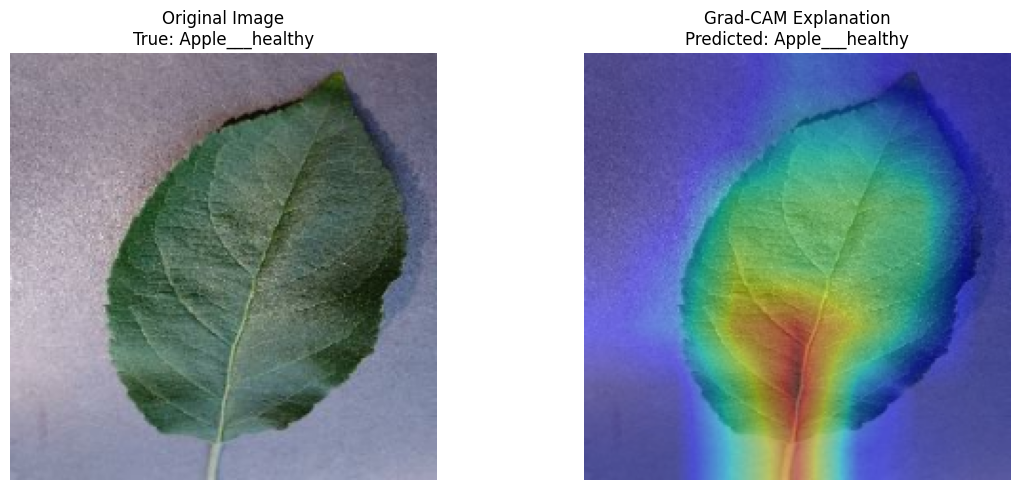

In [63]:
for i in range(5):

    sample_image = test_images[i]
    true_label = int(test_labels[i])

    heatmap, predicted_class, probabilities = make_gradcam_heatmap(
        sample_image,
        model,
        base_model
    )

    print(f"\nImage {i+1}")
    print("True disease     :", class_names[true_label])
    print("Predicted disease:", class_names[predicted_class])
    print(
        "Confidence       :",
        f"{np.max(probabilities) * 100:.2f}%"
    )

    display_gradcam(
        sample_image,
        heatmap,
        predicted_class,
        true_label
    )

Integrated Gradients

In [65]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


def integrated_gradients(
    image,
    pred_index=None,
    baseline=None,
    steps=50
):

    image_batch = tf.expand_dims(image, axis=0)

    if baseline is None:
        baseline = tf.zeros_like(image)

    baseline_batch = tf.expand_dims(baseline, axis=0)

    if pred_index is None:
        prediction = model(image_batch, training=False)
        pred_index = tf.argmax(prediction[0])

    alphas = tf.linspace(
        0.0,
        1.0,
        steps
    )

    interpolated_images = []

    for alpha in alphas:
        interpolated = (
            baseline_batch
            + alpha * (image_batch - baseline_batch)
        )
        interpolated_images.append(interpolated)

    interpolated_images = tf.concat(
        interpolated_images,
        axis=0
    )

    with tf.GradientTape() as tape:

        tape.watch(interpolated_images)

        predictions = model(
            interpolated_images,
            training=False
        )

        class_scores = predictions[:, pred_index]

    gradients = tape.gradient(
        class_scores,
        interpolated_images
    )

    avg_gradients = tf.reduce_mean(
        gradients,
        axis=0
    )

    integrated_grads = (
        image - baseline
    ) * avg_gradients

    attribution = tf.reduce_sum(
        tf.abs(integrated_grads),
        axis=-1
    )

    attribution = attribution / tf.maximum(
        tf.reduce_max(attribution),
        tf.keras.backend.epsilon()
    )

    return (
        attribution.numpy(),
        int(pred_index)
    )

In [66]:
ig_heatmap, ig_class = integrated_gradients(
    sample_image,
    pred_index=predicted_class,
    steps=50
)

print("True disease     :", class_names[true_label])
print("Predicted disease:", class_names[ig_class])

True disease     : Apple___healthy
Predicted disease: Apple___healthy


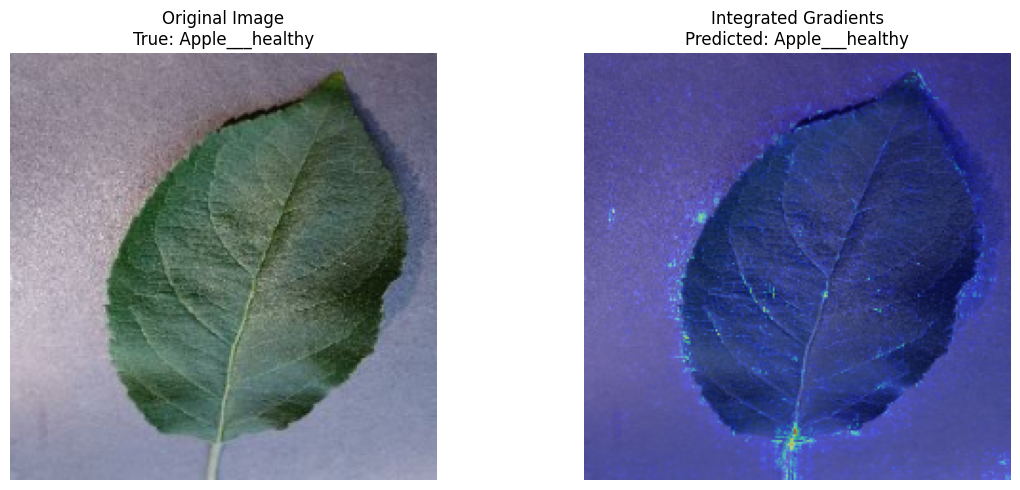

In [67]:
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(
    sample_image.numpy().astype("uint8")
)
plt.title(
    f"Original Image\n"
    f"True: {class_names[true_label]}"
)
plt.axis("off")

# Integrated Gradients
plt.subplot(1, 2, 2)
plt.imshow(
    sample_image.numpy().astype("uint8")
)
plt.imshow(
    ig_heatmap,
    cmap="jet",
    alpha=0.45
)
plt.title(
    f"Integrated Gradients\n"
    f"Predicted: {class_names[ig_class]}"
)
plt.axis("off")

plt.tight_layout()
plt.show()